# 1.2 Ingeniería de datos

Según el PIIC, esta actividad debe "determinar qué transformaciones benefician realmente al conjunto de datos" y probar limpieza, estandarización, normalización, balanceo y aumento de datos. Se parte de `datos/Data_corr_v6` (669 imágenes con las etiquetas corregidas).

**Criterio de trabajo:** se decide en papel todo lo que no requiere entrenar, y se experimenta solo con lo que sí.

| Transformación | Cómo se decide | Sección |
| :--- | :--- | :---: |
| Limpieza de etiquetas | Ya realizada (`1.2_limpieza_etiquetas`) | — |
| Consolidación a 2 clases | Analítica (EDA y Codex) | 1 |
| Partición | Por lote de captura, con un test que no se usa para decidir | 2 |
| Estandarización geométrica (letterbox) | Analítica (requisito de YOLO) | 3 |
| Resolución 640 / 960 / 1280 | **Experimento** | 3 y 7 |
| Normalización fotométrica (Gray World) | **Experimento** | 4 y 7 |
| Balanceo de clases | **Experimento** | 5 y 7 |
| Aumento de datos | Analítica: en línea (Ultralytics) | 6 |
| Normalización de píxeles a [0, 1] | La hace el dataloader de Ultralytics | — |

Las corridas de los experimentos se ejecutan en Google Colab con `nube/1.2_experimentos_colab.ipynb`; su análisis, en `1.2_experimentos.ipynb`.

In [1]:
import sys, json, shutil, zipfile
from pathlib import Path

RAIZ = Path.cwd(); sys.path.insert(0, str(RAIZ))
SALIDA = RAIZ / 'salida' / '1.2_ingenieria_datos'
PARTICION = RAIZ / 'resultados' / 'particion.json'

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display
import comun as C

DATOS, TRABAJO = C.DATOS, C.TRABAJO
LIMPIO = DATOS / 'Data_corr_v6'
ORIGINAL = C.ORIGINALES / 'Data_original'
C.estilo()
PALETA = C.paleta_clases()
inv = C.leer_dataset(LIMPIO)
maiz = [r for r in inv if any(c in C.CLASES_MAIZ for c in r['clases'])]
excluidas = [r for r in inv if r['clases'] and not any(c in C.CLASES_MAIZ for c in r['clases'])]
mixtas = [r for r in maiz if any(c not in C.CLASES_MAIZ for c in r['clases'])]
capturas = [r['stem'] for r in inv]   # todas las fotos: definen los lotes de captura
print(f'{len(inv)} imágenes: {len(maiz)} con maíz, {len(excluidas)} solo con impurezas u otras semillas, '
      f'{len(mixtas)} mixtas (se conservan solo sus cajas de maíz)')

669 imágenes: 513 con maíz, 156 solo con impurezas u otras semillas, 9 mixtas (se conservan solo sus cajas de maíz)


## 1. Consolidación a 2 clases

`Healthy` + `Immature` → **Healthy**; `Broken`, `Damage`, `Fungus`, `Shriveled` y `Weeveled` → **Defect**. Las imágenes que solo contienen impurezas u otras semillas se retiran: dejarlas con etiquetas vacías enseñaría a la red a ignorar objetos de forma parecida a los granos. Quedan reservadas como posibles fondos negativos para el OE2.

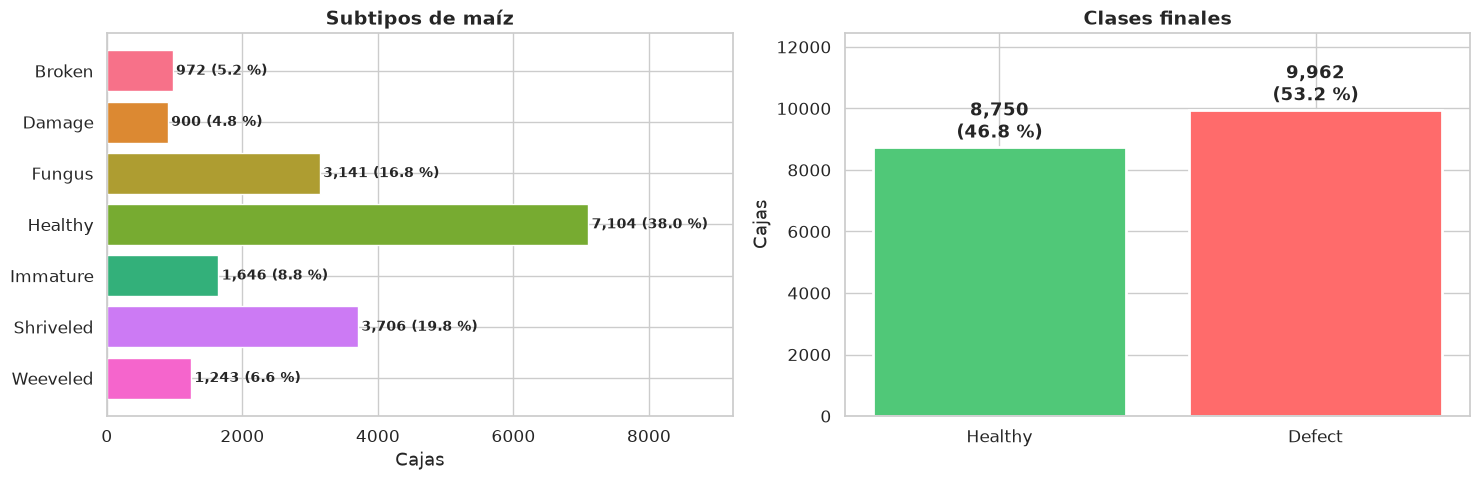

Razón Defect/Healthy: 1.14


In [2]:
sub = Counter(C.CLASES[c] for r in maiz for c in r['clases'] if c in C.CLASES_MAIZ)
binario = Counter()
for k, n in sub.items():
    binario[C.CLASES_BINARIAS[C.MAPEO_BINARIO[C.CLASES.index(k)]]] += n
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
orden = [C.CLASES[i] for i in C.SUBTIPOS]
ejes[0].barh(orden, [sub[c] for c in orden], color=[PALETA[c] for c in orden], edgecolor='white')
for i, c in enumerate(orden):
    ejes[0].text(sub[c] + 50, i, f'{sub[c]:,} ({100 * sub[c] / sum(sub.values()):.1f} %)', va='center', fontsize=10, fontweight='bold')
ejes[0].invert_yaxis(); ejes[0].set_xlim(0, max(sub.values()) * 1.3); ejes[0].set_title('Subtipos de maíz'); ejes[0].set_xlabel('Cajas')
b = ejes[1].bar(C.CLASES_BINARIAS, [binario[c] for c in C.CLASES_BINARIAS], color=[C.COLOR_BINARIO[c] for c in C.CLASES_BINARIAS],
                edgecolor='white', linewidth=2)
for barra, c in zip(b, C.CLASES_BINARIAS):
    ejes[1].text(barra.get_x() + barra.get_width() / 2, binario[c] + 100, f'{binario[c]:,}\n({100 * binario[c] / sum(binario.values()):.1f} %)',
                 ha='center', va='bottom', fontweight='bold')
ejes[1].set_ylim(0, max(binario.values()) * 1.25); ejes[1].set_title('Clases finales'); ejes[1].set_ylabel('Cajas')
C.guardar(SALIDA, 'consolidacion_2clases.png')
print(f"Razón Defect/Healthy: {binario['Defect'] / binario['Healthy']:.2f}")

## 2. Partición por lote de captura

La partición original de Roboflow tenía fuga: fotos de la misma bandeja en splits distintos (EDA, sección 8). Además, fotos tomadas con pocos minutos de diferencia suelen ser el mismo lote de granos reacomodado. Por eso la unidad de partición es el **lote**: fotos separadas por 5 minutos o menos (o hasta 5 posiciones de contador).

Los lotes se calculan con **las 669 fotos**, antes de retirar las de impurezas y otras semillas. Una foto retirada puede ser la que une dos capturas consecutivas del mismo lote: si se calcularan después, aparecerían saltos artificiales y un mismo lote podría quedar repartido entre conjuntos.

1. **Test (~15 %):** lotes completos, estratificados por subtipo. **No se usa en ninguna decisión** hasta la evaluación final del OE2.
2. **Desarrollo (~85 %):** 4 pliegues por lote para la validación cruzada.

Se prueban 300 semillas de `StratifiedGroupKFold` y se elige la que mejor representa al subtipo peor cubierto. Solo se usan las etiquetas, nunca un modelo.

In [3]:
part = C.particionar(maiz, capturas, fraccion_test=0.15, k=4)
PARTICION.parent.mkdir(exist_ok=True)
PARTICION.write_text(json.dumps(part, indent=1, ensure_ascii=False))
resumen = C.resumen_particion(part)
resumen

,conjunto,imágenes,lotes,cajas,% Healthy,Broken,Damage,Fungus,Healthy,Immature,Shriveled,Weeveled
0,test,54,5,2781,35.4,13.4,10.7,16.6,21.4,14.0,14.0,9.9
1,pliegue 0,120,1,3598,50.0,0.0,0.0,25.0,49.2,0.8,25.0,0.0
2,pliegue 1,120,1,3601,50.2,0.0,0.0,24.8,50.2,0.0,25.0,0.0
3,pliegue 2,115,7,4242,47.9,4.1,5.0,19.7,35.1,12.8,14.7,8.4
4,pliegue 3,104,5,4490,47.4,9.4,8.6,1.1,32.1,15.3,19.9,13.6
5,global,513,19,18712,46.8,5.2,4.8,16.8,38.0,8.8,19.8,6.6


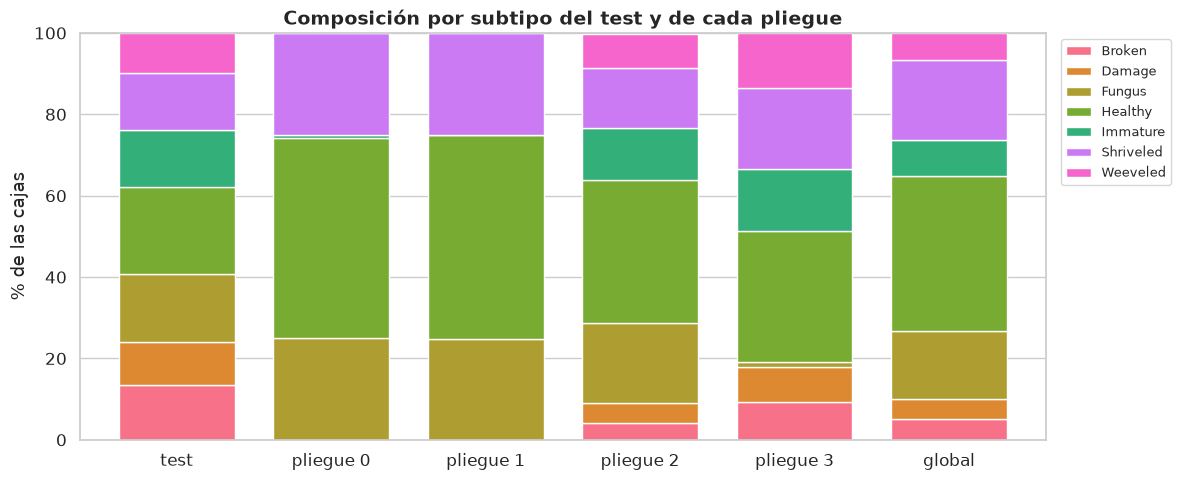

Lotes repartidos entre conjuntos: 0 (debe ser 0)
Lotes con maíz: 19 | tamaño (imágenes): [120, 120, 60, 43, 36, 24, 24, 15, 12, 12, 10, 8, 8, 6, 5, 5, 2, 2, 1]


In [4]:
orden = [C.CLASES[i] for i in C.SUBTIPOS]
r = resumen.set_index('conjunto')[orden]
ax = r.plot(kind='bar', stacked=True, figsize=(12, 5), color=[PALETA[c] for c in orden], edgecolor='white', width=0.75)
ax.set_ylabel('% de las cajas'); ax.set_xlabel(''); ax.set_title('Composición por subtipo del test y de cada pliegue')
ax.legend(bbox_to_anchor=(1.01, 1), fontsize=9); ax.tick_params(axis='x', rotation=0)
C.guardar(SALIDA, 'particion_composicion.png')
lotes = {}
for s, v in part['imagenes'].items():
    lotes.setdefault(v['lote'], set()).add('test' if v['conjunto'] == 'test' else f"p{v['pliegue']}")
print('Lotes repartidos entre conjuntos:', sum(len(x) > 1 for x in lotes.values()), '(debe ser 0)')
print('Lotes con maíz:', len(lotes), '| tamaño (imágenes):', sorted(Counter(v['lote'] for v in part['imagenes'].values()).values(), reverse=True))

## 3. Estandarización: letterbox y resolución

Las 9 resoluciones originales (unos 13.8 MP) se llevan a una resolución común con letterbox: se escala el lado mayor conservando la proporción y se rellena con gris (114, 114, 114) hasta un múltiplo de 32. Así no se deforma el grano ni se pierde ninguna caja. Se generan tres resoluciones y las dos variantes fotométricas: 640 px, la resolución por defecto de YOLO, y las dos candidatas del EDA, 960 y 1280 px (sección 4).

Cada dataset guarda `labels/` (clase binaria) y `labels_subtipo/` (subtipo original en la misma línea), para medir el acierto por subtipo.

In [5]:
n = C.generar_datasets(maiz, part, DATOS, resoluciones=C.FACTORES['resolucion'], variantes=C.FACTORES['fotometrico'])
filas = []
for res in C.FACTORES['resolucion']:
    for v in C.FACTORES['fotometrico']:
        d = DATOS / f'Data_2c_{res}_{v}'
        for conj in ('dev', 'test'):
            imgs = sorted((d / conj / 'images').glob('*.jpg'))
            cajas = sum(len(C.leer_yolo(p)[0]) for p in (d / conj / 'labels').glob('*.txt'))
            filas.append({'dataset': d.name, 'conjunto': conj, 'imágenes': len(imgs), 'cajas': cajas})
pd.DataFrame(filas)

,dataset,conjunto,imágenes,cajas
0,Data_2c_640_base,dev,459,15931
1,Data_2c_640_base,test,54,2781
2,Data_2c_640_norm,dev,459,15931
3,Data_2c_640_norm,test,54,2781
4,Data_2c_960_base,dev,459,15931
5,Data_2c_960_base,test,54,2781
6,Data_2c_960_norm,dev,459,15931
7,Data_2c_960_norm,test,54,2781
8,Data_2c_1280_base,dev,459,15931
9,Data_2c_1280_base,test,54,2781


## 4. Normalización fotométrica

Variante `norm`: balance de blancos Gray World, brillo objetivo, contraste y saturación. Corrige el tinte violáceo de algunas capturas, pero altera el color natural del grano en las que ya estaban bien. Su efecto se mide en el experimento.

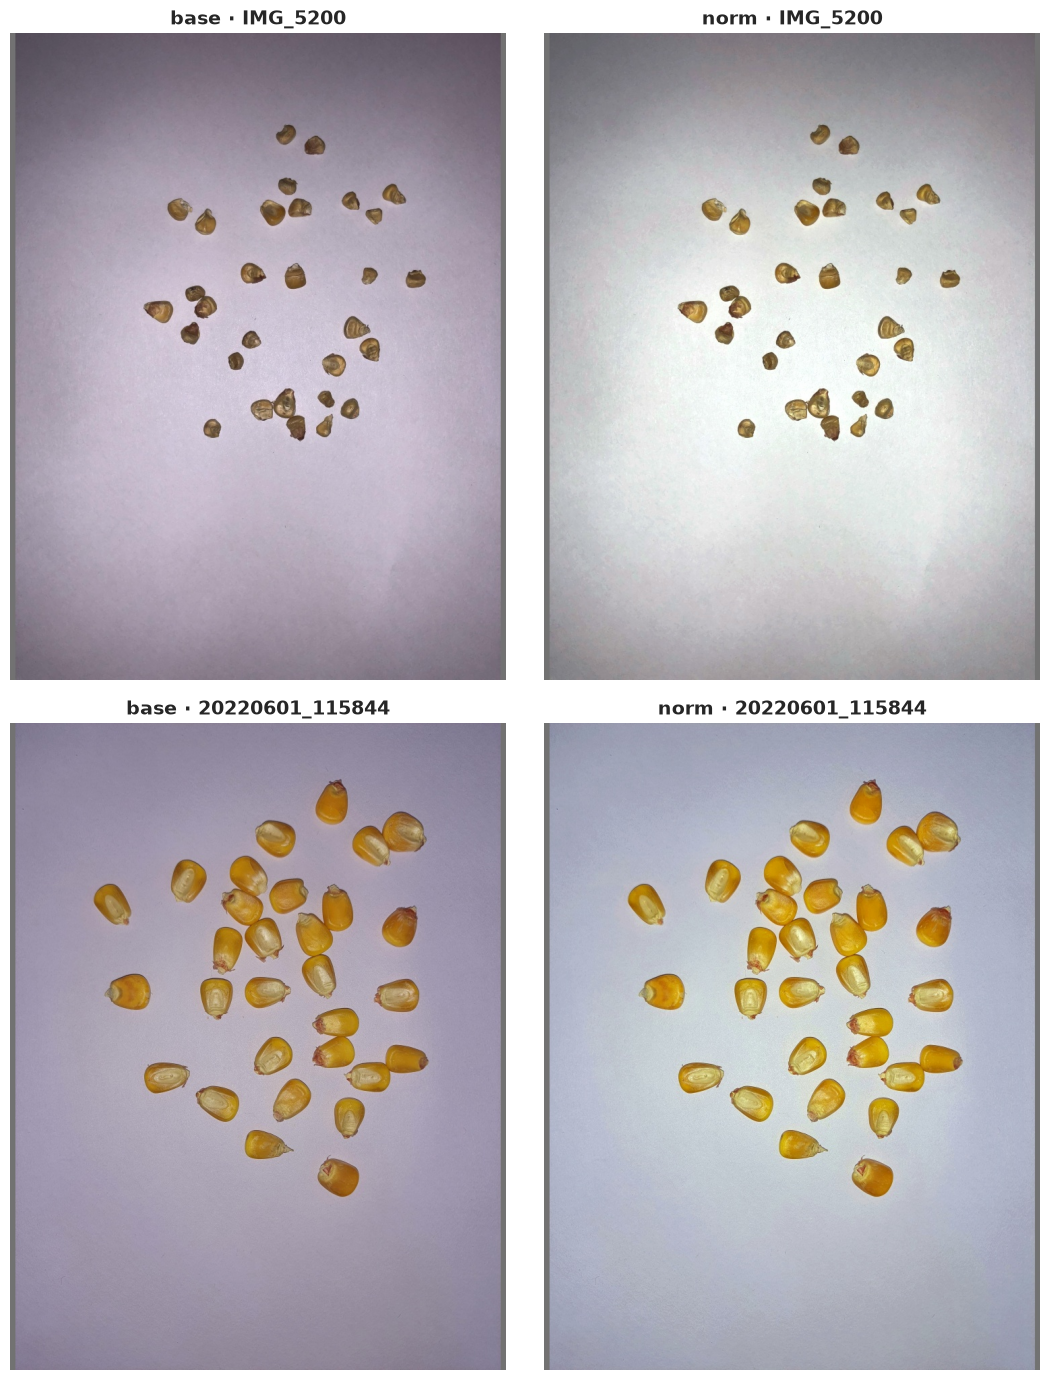

In [6]:
ej = sorted((DATOS / 'Data_2c_960_base' / 'dev' / 'images').glob('*.jpg'))
ej = [p for p in ej if p.stem.startswith('IMG_52')][:1] + [p for p in ej if p.stem.startswith('20220601_11')][:1]
fig, ejes = plt.subplots(len(ej), 2, figsize=(11, 7 * len(ej)))
for fila, p in zip(ejes, ej):
    for ax, v in zip(fila, ('base', 'norm')):
        img = cv2.imread(str(DATOS / f'Data_2c_960_{v}' / 'dev' / 'images' / p.name))
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.axis('off'); ax.set_title(f'{v} · {C.nombre_roboflow(p.stem)}')
C.guardar(SALIDA, 'normalizacion_base_vs_norm.png')

## 5. Balanceo de clases

Sobremuestreo por déficit dentro de cada pliegue: se copian imágenes de la clase deficitaria (priorizando las que más cajas de esa clase tienen) hasta igualar las cajas de `Healthy` y `Defect`.

Las copias **no repiten el aumento en línea de Ultralytics**. Usan solo transformaciones que Ultralytics no aplica por defecto, para no ser duplicados exactos de imágenes que el entrenamiento ya varía: rotación de 90/180/270°, volteo vertical, y una de estas: ruido de sensor, compresión JPEG, gamma, nitidez o curva tonal.

In [7]:
filas = []
for k in range(part['k']):
    exp = {'resolucion': 960, 'fotometrico': 'base', 'balanceo': 'bal', 'aumento': 'sinaum', 'pliegue': k}
    _, _, n_base, n_train = C.preparar_pliegue(exp, part, DATOS, TRABAJO)
    cajas = Counter()
    for s, v in part['imagenes'].items():
        if v['conjunto'] == 'dev' and v['pliegue'] != k:
            _, cl = C.leer_yolo(DATOS / 'Data_2c_960_base' / 'dev' / 'labels' / f'{s}.txt'); cajas.update(cl)
    filas.append({'pliegue': k, 'imágenes de entrenamiento': n_base, 'Healthy': cajas[0], 'Defect': cajas[1],
                  'Defect / Healthy': round(cajas[1] / cajas[0], 2), 'copias de balanceo': n_train - n_base})
pd.DataFrame(filas)

,pliegue,imágenes de entrenamiento,Healthy,Defect,Defect / Healthy,copias de balanceo
0,0,339,5966,6367,1.07,6
1,1,339,5958,6372,1.07,6
2,2,344,5733,5956,1.04,3
3,3,355,5638,5803,1.03,1


## 6. Aumento de datos: en línea

Ultralytics aplica aumento **en línea** en cada época: mosaico, volteo horizontal, escala, traslación y variación de tono, saturación y brillo (HSV). Cada imagen se ve con una variante distinta en cada época, sin ocupar disco. No se genera un dataset aumentado offline, por dos razones:

1. **Sería redundante.** Copias offline con esas mismas transformaciones solo repiten lo que el entrenamiento ya hace, con menos variedad, porque quedan congeladas en disco.
2. **Fuga.** En la literatura de maíz es habitual multiplicar el dataset offline, a veces antes de partirlo, de modo que versiones de una misma imagen acaban en entrenamiento y en prueba. Aquí, las únicas copias offline son las del balanceo, y se generan dentro de cada pliegue, solo a partir de imágenes de entrenamiento.

Ejemplos de las transformaciones que usan las copias de balanceo (zona de los granos):

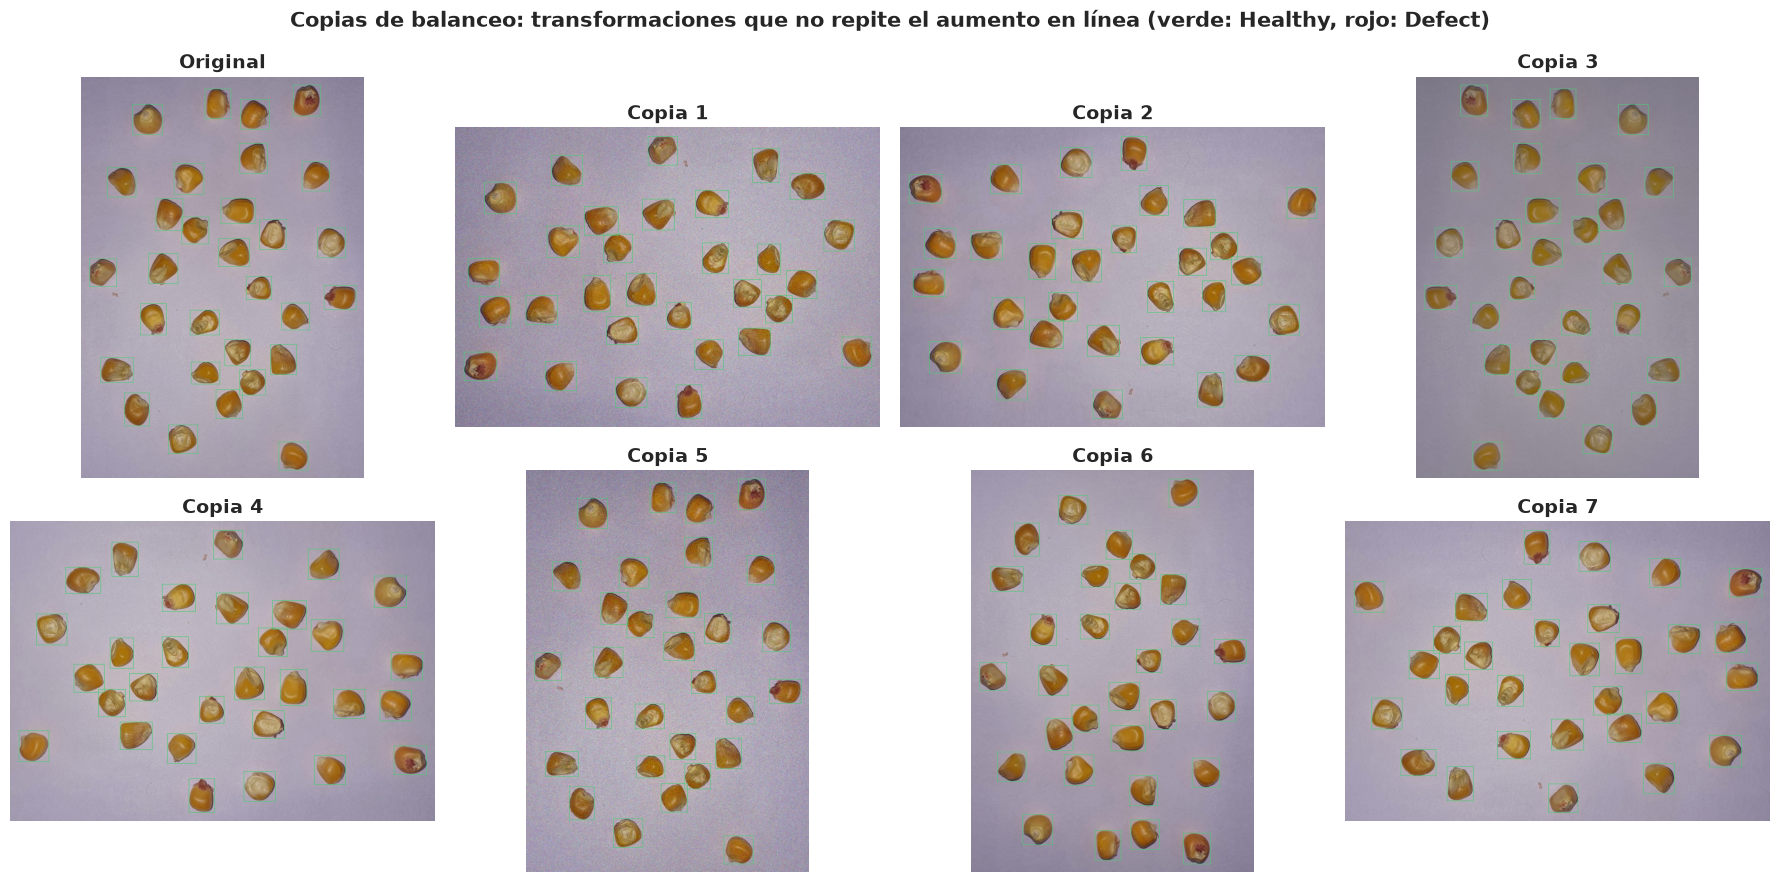

In [8]:
p = sorted((DATOS / 'Data_2c_960_base' / 'dev' / 'images').glob('*.jpg'))[40]
cajas, clases = C.leer_yolo(p.parent.parent / 'labels' / f'{p.stem}.txt')
img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
t = C.transformacion_unica(); t.set_random_seed(3)
fig, ejes = plt.subplots(2, 4, figsize=(18, 9))
for i, ax in enumerate(ejes.flat):
    out = {'image': img, 'bboxes': cajas, 'clases': clases} if i == 0 else t(image=img, bboxes=cajas, clases=clases)
    vis = out['image'].copy(); H, W = vis.shape[:2]
    b = np.array(out['bboxes']); x1, y1 = (b[:, 0] - b[:, 2] / 2).min() * W, (b[:, 1] - b[:, 3] / 2).min() * H
    x2, y2 = (b[:, 0] + b[:, 2] / 2).max() * W, (b[:, 1] + b[:, 3] / 2).max() * H
    for (cx, cy, w, h), c in zip(out['bboxes'], out['clases']):
        col = (80, 200, 120) if int(c) == 0 else (255, 107, 107)
        cv2.rectangle(vis, (int((cx - w / 2) * W), int((cy - h / 2) * H)), (int((cx + w / 2) * W), int((cy + h / 2) * H)), col, 1)
    m = 15
    ax.imshow(vis[max(0, int(y1) - m):int(y2) + m, max(0, int(x1) - m):int(x2) + m]); ax.axis('off')
    ax.set_title('Original' if i == 0 else f'Copia {i}')
fig.suptitle('Copias de balanceo: transformaciones que no repite el aumento en línea (verde: Healthy, rojo: Defect)', fontsize=15, fontweight='bold')
C.guardar(SALIDA, 'copias_balanceo_ejemplos.png')

## 7. Diseño experimental

**Factores:**

| Factor | Niveles |
| :--- | :--- |
| Resolución | 640, 960, 1280 |
| Fotométrico | `base`, `norm` |
| Balanceo | `sinbal`, `bal` |

**Diseño factorial completo 3 × 2 × 2:** 12 configuraciones × 4 pliegues × 3 semillas (13, 29 y 51) = **144 corridas**. Se estiman los tres efectos principales y todas sus interacciones.

**Protocolo fijo:** YOLOv11s preentrenado en COCO, SGD con `lr0 = 0.01`, aumento en línea por defecto de Ultralytics, lote 8 y sin parada temprana. Sin balanceo se entrenan 50 épocas; con balanceo, las épocas se reducen en proporción a las copias añadidas (mismo número de iteraciones). Las semillas se fijan antes de entrenar y todas las configuraciones usan las mismas; las copias del balanceo son las mismas para las tres.

**Métrica de decisión:** mAP50-95 en el pliegue de validación. Se registran también mAP50, P, R, el acierto por subtipo y el MAE de conteo (NMS agnóstico).

**Análisis:** modelo lineal con los tres factores, sus interacciones y cada combinación de pliegue y semilla como bloque.

**Regla de decisión** (fijada antes de entrenar, la misma para los tres factores): se parte de la configuración más simple (640, `base`, `sinbal`) y un nivel más costoso o complejo solo se adopta si **mejora el mAP50-95 en al menos +0.005 y la mejora es significativa** (p < 0.05). La resolución se recorre en orden (640 → 960 → 1280), comparando siempre con el nivel vigente.
- Sin interacciones significativas, cada factor se decide por separado con sus efectos principales.
- Con alguna interacción significativa, el efecto de un factor depende de otro, y se comparan configuraciones completas: desde la vigente, se pasa a la más simple de las que la superan con la misma regla (t pareada por pliegue y semilla, corrección de Holm), hasta que ninguna la supere.

**Experimentos complementarios** (sobre la configuración elegida, 4 pliegues × 3 semillas = 12 corridas cada uno): para comprobar experimentalmente las dos técnicas que se aplican sin pasar por el diseño factorial, se entrena quitando cada una y se compara con las corridas del diseño en los mismos pliegues y semillas:
- **Limpieza de etiquetas:** entrenamiento con las etiquetas originales (v0) en lugar de las corregidas (sección 8).
- **Aumento en línea:** entrenamiento sin ningún aumento de Ultralytics.

**Ejecución:** las 168 corridas (144 del diseño y 24 complementarias) en Google Colab, con la misma GPU (NVIDIA A100).

In [9]:
print(len(C.matriz_experimentos(part)), 'corridas del diseño factorial; semillas', C.SEMILLAS)
pd.DataFrame(C.configuraciones())

144 corridas del diseño factorial; semillas (13, 29, 51)


,resolucion,fotometrico,balanceo
0,640,base,sinbal
1,640,base,bal
2,640,norm,sinbal
3,640,norm,bal
4,960,base,sinbal
5,960,base,bal
6,960,norm,sinbal
7,960,norm,bal
8,1280,base,sinbal
9,1280,base,bal


## 8. Dataset con las etiquetas originales

Para el experimento complementario de limpieza se genera la configuración elegida con las **mismas imágenes y el mismo preprocesamiento**, pero con las etiquetas de la versión original (v0) en lugar de las corregidas (v3). Solo cambian las etiquetas: las cajas omitidas, duplicadas, degeneradas o con la clase mal asignada que se corrigieron en las tres rondas de limpieza.

El entrenamiento usa estas etiquetas; la validación usa siempre las corregidas, para medir el efecto de la limpieza frente a la verdad de referencia. Se genera cuando el diseño factorial ya decidió la configuración (`resultados/decision.json`).

In [10]:
decision_json = RAIZ / 'resultados' / 'decision.json'
if decision_json.exists():
    decision = json.loads(decision_json.read_text())
    RES, FOTO = decision['resolucion']['elegido'], decision['fotometrico']['elegido']
    maiz_v0 = C.con_etiquetas_originales(maiz, ORIGINAL)
    C.generar_datasets(maiz_v0, part, DATOS / 'etiquetas_v0', resoluciones=(RES,), variantes=(FOTO,))

    dev = [r for r in maiz if part['imagenes'][r['stem']]['conjunto'] == 'dev']
    filas = []
    for nombre, regs in (('original (v0)', C.con_etiquetas_originales(dev, ORIGINAL)), ('corregida (v3)', dev)):
        sub = Counter(c for r in regs for c in r['clases'] if c in C.CLASES_MAIZ)
        b = Counter(C.CLASES_BINARIAS[C.MAPEO_BINARIO[c]] for c in sub.elements())
        filas.append({'etiquetas': nombre, 'imágenes': len(regs), 'cajas de maíz': sum(sub.values()), **b,
                      'imágenes sin cajas de maíz': sum(not any(c in C.CLASES_MAIZ for c in r['clases']) for r in regs)})
    display(pd.DataFrame(filas).set_index('etiquetas'))
else:
    print('Pendiente: se genera cuando exista resultados/decision.json.')

,imágenes,cajas de maíz,Defect,Healthy,imágenes sin cajas de maíz
etiquetas,,,,,
original (v0),459,15906,8513,7393,0
corregida (v3),459,15931,8166,7765,0


## 9. Paquete para la nube

Genera `nube/oe1_nube.zip` con lo necesario para correr `nube/1.2_experimentos_colab.ipynb` en Colab:
- el código (`comun.py`), la partición y, si existen, el registro de corridas y la decisión (la nube omite las corridas ya registradas);
- los 6 datasets (`Data_2c_<resolución>_<variante>`), solo `dev`: el test no se usa en los experimentos. Con la decisión tomada, solo el de la configuración elegida;
- el dataset con las etiquetas originales, cuando ya existe (experimentos complementarios).

Se sube a Google Drive.

In [11]:
zip_nube = C.NUBE / 'oe1_nube.zip'
zip_nube.parent.mkdir(exist_ok=True)
archivos = [RAIZ / 'comun.py', PARTICION]
archivos += [p for p in (RAIZ / 'resultados' / 'experimentos.csv', RAIZ / 'resultados' / 'decision.json') if p.exists()]
archivos += sorted(p for p in (DATOS / 'etiquetas_v0').rglob('*') if p.is_file() and '/test/' not in str(p))
# Con la decisión tomada, los complementarios solo necesitan la configuración elegida
variantes = ([(RES, FOTO)] if decision_json.exists() else
             [(res, v) for res in C.FACTORES['resolucion'] for v in C.FACTORES['fotometrico']])
for res, v in variantes:
    archivos += sorted(p for p in (DATOS / f'Data_2c_{res}_{v}' / 'dev').rglob('*') if p.is_file())
with zipfile.ZipFile(zip_nube, 'w') as z:
    for p in archivos:
        z.write(p, Path(C.REPO.name) / p.relative_to(C.REPO),
                compress_type=zipfile.ZIP_STORED if p.suffix == '.jpg' else zipfile.ZIP_DEFLATED)
print(f'{zip_nube} ({zip_nube.stat().st_size / 1e6:.0f} MB, {len(archivos)} archivos)')

/home/ismael/Documents/Tesis/maiz-yolo11-v2/nube/oe1_nube.zip (301 MB, 2758 archivos)
